# Phase 1 — EDA and ETL (corrected, 55C-V2)
**Project:** Machine Learning for Chronic Stockout Risk Assessment: Implications for Quick-Commerce Inventory Planning  
**Team:** Nishant Khandelwal, Anwesha Banerjee, Anisha Saha  
**Purpose:** Audit the *original* simulated SKU-level data, verify the supplied chronic stockout label, and export only eligible features for Phase 2.  

**Scope:** This is *classification of a supplied summary-record label*, **not** validated prediction of future cycles or evidence of reduced inventory cost. This notebook deliberately does **not** standardise, encode, impute, or otherwise fit transformations on the complete dataset. Phase 2 must fit all learned preprocessing inside training folds.

**Input:** `inventory_optimization.csv` in the **same folder** as this notebook. Do not use the previous `cleaned_inventory_optimization.csv` as input.

## 1. Import libraries and read the original dataset

In [4]:
from pathlib import Path
import hashlib, json, platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RAW_PATH = Path("inventory_optimization.csv")
MODEL_INPUT_PATH = Path("cleaned_inventory_optimization.csv")
AUDIT_PATH = Path("eda_audit_55C_V2.json")
FIGURE_DIR = Path("outputs/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not RAW_PATH.is_file():
    raise FileNotFoundError("Upload inventory_optimization.csv to the notebook's working directory before running.")
source_sha256 = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
df = pd.read_csv(RAW_PATH, low_memory=False)
print("Raw file:", RAW_PATH, "| SHA256:", source_sha256)
print("Dataset shape:", df.shape)
print("Duplicate full rows:", int(df.duplicated().sum()))
print("Missing values total:", int(df.isna().sum().sum()))
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
display(df.isna().sum().rename("missing_count").to_frame())

Raw file: inventory_optimization.csv | SHA256: bef1c3cd6d53ce8c4397bb47d0dc4564941ee842ecdf984dba696860948347a6
Dataset shape: (45000, 28)
Duplicate full rows: 0
Missing values total: 0
Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | seaborn 0.13.2


,sku_id,category,ignores_lead_time_variability,mean_daily_demand,sigma_daily_demand,demand_cv,mean_lead_time,sigma_lead_time,lead_time_cv,unit_cost,...,stockout_frequency,units_short,units_excess,holding_cost,shortage_cost,spoilage_cost,total_cost,optimal_service_level,service_level_gap,stockout_occurred
0,SKU000000,high_value,1,8.4,6.10,0.726,12.5,6.51,0.521,340.94,...,0.417,25.91,46.09,236.88,17594.70,0.00,17870.58,0.995,-0.095,1
1,SKU000001,perishable,1,9.9,4.49,0.454,17.8,10.39,0.584,15.95,...,0.250,9.83,34.80,13.43,175.37,222.02,499.82,0.988,-0.088,1
2,SKU000002,fast_mover,1,13.6,4.21,0.310,13.5,6.23,0.462,28.03,...,0.500,33.72,55.06,19.21,612.36,0.00,726.57,0.990,0.000,1
3,SKU000003,fast_mover,0,6.1,1.80,0.294,12.7,6.05,0.476,6.52,...,0.000,0.00,65.31,5.32,0.00,0.00,43.32,0.991,-0.091,0
4,SKU000004,seasonal,1,53.2,37.35,0.702,7.4,1.03,0.139,11.21,...,0.000,0.00,141.06,9.91,0.00,0.00,107.91,0.992,-0.092,0


,dtype
sku_id,object
category,object
ignores_lead_time_variability,int64
mean_daily_demand,float64
sigma_daily_demand,float64
demand_cv,float64
mean_lead_time,float64
sigma_lead_time,float64
lead_time_cv,float64
unit_cost,float64


,missing_count
sku_id,0
category,0
ignores_lead_time_variability,0
mean_daily_demand,0
sigma_daily_demand,0
demand_cv,0
mean_lead_time,0
sigma_lead_time,0
lead_time_cv,0
unit_cost,0


## 2. Verify the dataset-defined target (≥20% of replenishment cycles)
No positional fallback is allowed. The direct target and target-defining frequency are **not predictors**.

In [5]:
required_target_columns = ["stockout_frequency", "stockout_occurred"]
missing_target_columns = [c for c in required_target_columns if c not in df.columns]
if missing_target_columns:
    raise KeyError(f"Missing target columns: {missing_target_columns}")
if df[required_target_columns].isna().any().any():
    raise ValueError("Missing target values require investigation; do not silently impute them.")
if not df["stockout_frequency"].between(0, 1).all():
    raise ValueError("stockout_frequency contains values outside [0,1].")
if not df["stockout_occurred"].isin([0, 1]).all():
    raise ValueError("stockout_occurred must be binary 0/1.")
recomputed_label = (df["stockout_frequency"] >= 0.20).astype(int)
mismatch_count = int((recomputed_label != df["stockout_occurred"]).sum())
print("Label mismatches against threshold >= 0.20:", mismatch_count)
if mismatch_count:
    raise ValueError("Source target and target rule disagree. Investigate before training.")
counts = df["stockout_occurred"].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({"records": counts, "percent": (counts / len(df) * 100).round(2)}))

Label mismatches against threshold >= 0.20: 0


,records,percent
stockout_occurred,,
0,31202,69.34
1,13798,30.66


In [6]:

import pandas as pd
import hashlib
from pathlib import Path

path = Path("/content/inventory_optimization.csv")
df = pd.read_csv(path)

print("Dataset shape:", df.shape)
print("File size:", path.stat().st_size)
print("SHA256:", hashlib.sha256(path.read_bytes()).hexdigest())

print("\nMissing target values:")
print(df[["stockout_frequency", "stockout_occurred"]].isna().sum())


Dataset shape: (45000, 28)
File size: 7198915
SHA256: bef1c3cd6d53ce8c4397bb47d0dc4564941ee842ecdf984dba696860948347a6

Missing target values:
stockout_frequency    0
stockout_occurred     0
dtype: int64


## 3. Explicitly define the two feature sets and exclude leakage
**Core:** pre-outcome demand, lead-time, category, policy-design flag, and item/cost descriptors.  
**Policy augmented:** core + four candidate inventory-policy variables.  
**Excluded:** SKU identifier, target-definition field, realised outcomes, realised costs, and outcome-derived benchmark variables.

The policy-augmented experiment is a *sensitivity comparison*, not a causal evaluation of changing safety stock or reorder points.

In [7]:
CORE_FEATURES = [
    "category", "ignores_lead_time_variability", "mean_daily_demand",
    "sigma_daily_demand", "demand_cv", "mean_lead_time",
    "sigma_lead_time", "lead_time_cv", "unit_cost",
    "holding_rate_annual", "stockout_penalty", "order_cost",
]
POLICY_FEATURES = ["target_service_level", "safety_stock", "reorder_point", "order_quantity"]
TARGET = "stockout_occurred"
LEAKAGE_AND_EXCLUDED = [
    "sku_id", "stockout_frequency", "realized_demand_lt", "units_short", "units_excess",
    "holding_cost", "shortage_cost", "spoilage_cost", "total_cost",
    "optimal_service_level", "service_level_gap",
]
required_columns = CORE_FEATURES + POLICY_FEATURES + [TARGET]
missing_columns = sorted(set(required_columns).difference(df.columns))
if missing_columns:
    raise KeyError(f"Missing required approved columns: {missing_columns}. Check data dictionary; do not guess.")
assert not set(CORE_FEATURES + POLICY_FEATURES).intersection(LEAKAGE_AND_EXCLUDED + [TARGET])
print("Core features:", len(CORE_FEATURES), CORE_FEATURES)
print("Additional policy features:", len(POLICY_FEATURES), POLICY_FEATURES)
print("Excluded identifiers and outcome fields:", LEAKAGE_AND_EXCLUDED)
print("Other raw columns (must not enter the model by accident):", sorted(set(df.columns)-set(required_columns)-set(LEAKAGE_AND_EXCLUDED)))

Core features: 12 ['category', 'ignores_lead_time_variability', 'mean_daily_demand', 'sigma_daily_demand', 'demand_cv', 'mean_lead_time', 'sigma_lead_time', 'lead_time_cv', 'unit_cost', 'holding_rate_annual', 'stockout_penalty', 'order_cost']
Additional policy features: 4 ['target_service_level', 'safety_stock', 'reorder_point', 'order_quantity']
Excluded identifiers and outcome fields: ['sku_id', 'stockout_frequency', 'realized_demand_lt', 'units_short', 'units_excess', 'holding_cost', 'shortage_cost', 'spoilage_cost', 'total_cost', 'optimal_service_level', 'service_level_gap']
Other raw columns (must not enter the model by accident): []


## 4. Descriptive EDA
These plots describe the supplied simulated table. They do not establish causality or future stockout forecasting.

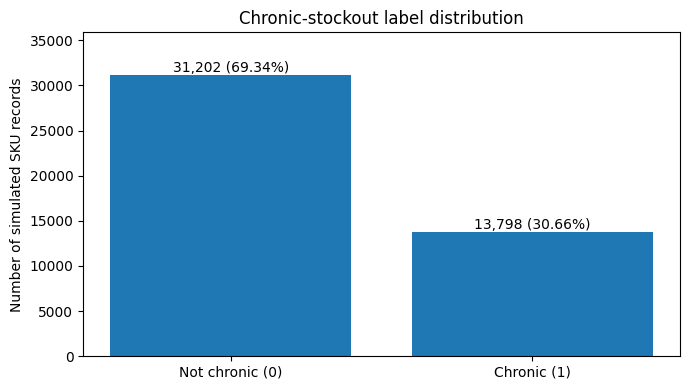

,records,chronic_rate,chronic_percent
category,,,
fast_mover,11656,0.438744,43.87
perishable,4574,0.357892,35.79
high_value,7167,0.287987,28.80
seasonal,7323,0.273112,27.31
slow_mover,8940,0.215660,21.57
spare_part,5340,0.197566,19.76


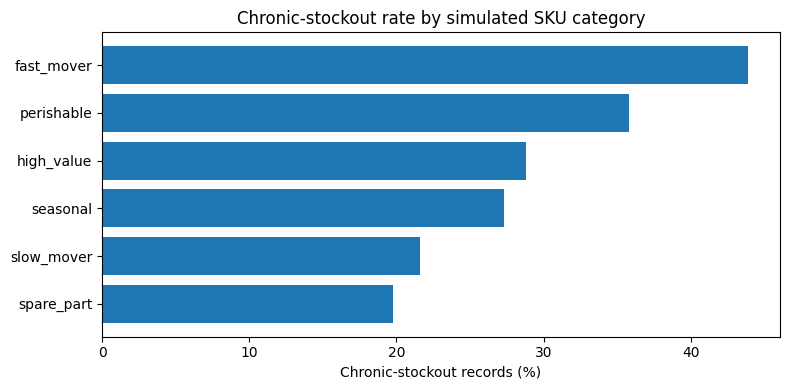

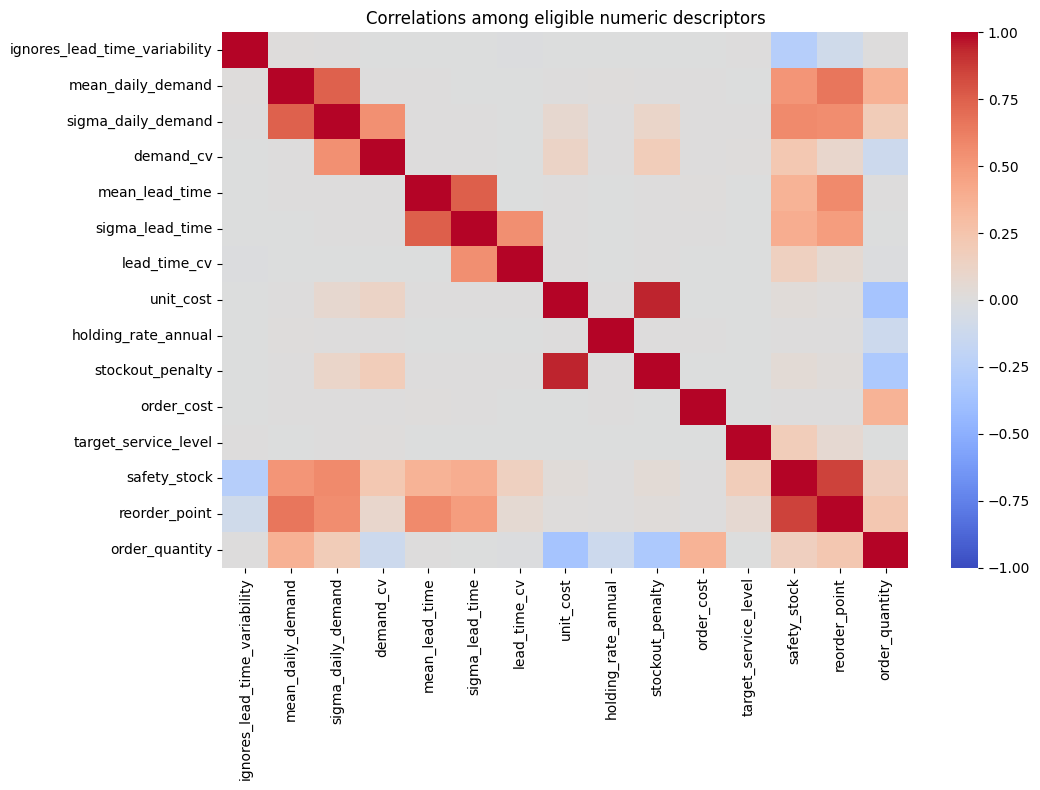

In [8]:
# Target distribution
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Not chronic (0)", "Chronic (1)"], counts.to_numpy())
for i, n in enumerate(counts):
    ax.text(i, int(n), f"{int(n):,} ({n/len(df):.2%})", ha="center", va="bottom")
ax.set_ylabel("Number of simulated SKU records")
ax.set_title("Chronic-stockout label distribution")
ax.set_ylim(0, max(counts)*1.15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "target_distribution.png", dpi=160)
plt.show()

# Actual target rate by category (descriptive)
category_rates = (df.groupby("category")[TARGET]
                  .agg(["size", "mean"])
                  .rename(columns={"size":"records", "mean":"chronic_rate"})
                  .sort_values("chronic_rate", ascending=False))
category_rates["chronic_percent"] = (100 * category_rates["chronic_rate"]).round(2)
display(category_rates)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(category_rates.index[::-1], category_rates["chronic_percent"].iloc[::-1])
ax.set_xlabel("Chronic-stockout records (%)")
ax.set_title("Chronic-stockout rate by simulated SKU category")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "category_rates.png", dpi=160)
plt.show()

# Correlation among eligible numeric descriptors only
num_features = [c for c in CORE_FEATURES + POLICY_FEATURES if pd.api.types.is_numeric_dtype(df[c])]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(df[num_features].corr(), vmin=-1, vmax=1, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlations among eligible numeric descriptors")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "eligible_feature_correlations.png", dpi=160)
plt.show()

## 5. Export the Phase 2 model-input table and an audit file
Outputs use **raw measurement scales** and retain only the 16 approved predictors plus the verified target. The old `cleaned_inventory_optimization.csv` will be overwritten, so only run this notebook once you have archived the old version if you want to keep it. For Phase 2, apply stratified **70/15/15** train/validation/test splitting, then fit imputation, scaling, and encoding on training data only.

In [9]:
model_input = df.loc[:, CORE_FEATURES + POLICY_FEATURES + [TARGET]].copy()
assert model_input.shape == (len(df), len(CORE_FEATURES)+len(POLICY_FEATURES)+1)
assert not set(LEAKAGE_AND_EXCLUDED).intersection(model_input.columns)
model_input.to_csv(MODEL_INPUT_PATH, index=False)

versions = {"python": platform.python_version(), "pandas": pd.__version__,
            "numpy": np.__version__, "matplotlib": plt.matplotlib.__version__,
            "seaborn": sns.__version__}
audit = {
    "project_id": "55C-V2", "raw_source": RAW_PATH.name,
    "sha256": source_sha256,
    "raw_shape": list(df.shape), "full_row_duplicates": int(df.duplicated().sum()),
    "missing_cells": int(df.isna().sum().sum()),
    "target_rule": "stockout_frequency >= 0.20",
    "target_rule_mismatches": mismatch_count,
    "target_counts": {str(k): int(v) for k,v in counts.items()},
    "core_features": CORE_FEATURES, "policy_features": POLICY_FEATURES,
    "excluded_columns": LEAKAGE_AND_EXCLUDED,
    "model_input_shape": list(model_input.shape),
    "versions": versions,
    "interpretation_limit": "Classification of a supplied simulated summary-record label; not temporal forecasting or causal evidence."
}
AUDIT_PATH.write_text(json.dumps(audit, indent=2), encoding="utf-8")
print("SUCCESS. Phase 2 input:", MODEL_INPUT_PATH, "shape:", model_input.shape)
print("Audit file:", AUDIT_PATH)
print("Figures in:", FIGURE_DIR)
print("No full-dataset imputation, scaling, or encoding performed.")
display(model_input.head())

SUCCESS. Phase 2 input: cleaned_inventory_optimization.csv shape: (45000, 17)
Audit file: eda_audit_55C_V2.json
Figures in: outputs/figures
No full-dataset imputation, scaling, or encoding performed.


,category,ignores_lead_time_variability,mean_daily_demand,sigma_daily_demand,demand_cv,mean_lead_time,sigma_lead_time,lead_time_cv,unit_cost,holding_rate_annual,stockout_penalty,order_cost,target_service_level,safety_stock,reorder_point,order_quantity,stockout_occurred
0,high_value,1,8.4,6.10,0.726,12.5,6.51,0.521,340.94,0.287,679.07,39.0,0.90,24.6,129.6,55.0,1
1,perishable,1,9.9,4.49,0.454,17.8,10.39,0.584,15.95,0.284,17.84,89.0,0.90,26.0,202.2,403.0,1
2,fast_mover,1,13.6,4.21,0.310,13.5,6.23,0.462,28.03,0.183,18.16,95.0,0.99,46.2,229.8,512.0,1
3,fast_mover,0,6.1,1.80,0.294,12.7,6.05,0.476,6.52,0.198,5.02,38.0,0.90,53.1,130.6,535.0,0
4,seasonal,1,53.2,37.35,0.702,7.4,1.03,0.139,11.21,0.166,4.81,98.0,0.90,121.7,515.4,1843.0,0


### What to save to GitHub after successful execution
- Replace `EDA_and_ETL_Pipeline.ipynb` with this notebook, **saved with outputs**.
- Replace the old `cleaned_inventory_optimization.csv` with the newly exported one.
- Add `eda_audit_55C_V2.json` and generated charts under `outputs/figures/`.
- Keep the original `inventory_optimization.csv` unchanged.

Do **not** train models in Phase 1. Model fitting, validation and all performance claims belong in Phase 2.